# Analisis Faktor yang Memengaruhi Waktu Pengiriman Makanan

**Take Home Test Data Analyst**

| | |
|---|---|
| Nama | Prabaswara Trirespati |
| Program | Data Analyst & Business Intelligence Bootcamp, Dibimbing.id (DABI 23) |
| Dataset | [Food Delivery Time Prediction (Kaggle)](https://www.kaggle.com/datasets/denkuznetz/food-delivery-time-prediction) |
| Tools | Python (Google Colab), Power BI |

**Isi notebook:**
1. Pemahaman Masalah dan Problem Statement
2. Data Preprocessing
3. Exploratory Data Analysis (EDA)
4. Insight dan Interpretasi
5. Rekomendasi Bisnis
6. Kesimpulan dan Catatan untuk Dashboard

## Tahap 1. Pemahaman Masalah dan Problem Statement

### Latar Belakang
Di bisnis food delivery, kecepatan pengiriman adalah salah satu hal yang paling dirasakan langsung oleh pelanggan. Makanan yang datang terlalu lama biasanya sudah dingin, pelanggan jadi kecewa, dan kemungkinan mereka pesan lagi ikut turun. Dari sisi perusahaan, pengiriman yang lama juga berarti kurir lebih sedikit menyelesaikan order per jam.

Dataset ini berisi 1.000 data order pengiriman makanan beserta kondisi saat pengiriman, seperti jarak, cuaca, kepadatan lalu lintas, waktu dalam sehari, jenis kendaraan, lama persiapan makanan di restoran, dan pengalaman kurir. Variabel target yang dianalisis adalah **`Delivery_Time_min`**, yaitu total waktu pengiriman dalam menit.

### Problem Statement
Perusahaan belum tahu secara pasti **faktor apa saja yang paling membuat pengiriman menjadi lama**. Tanpa informasi ini, perusahaan sulit menentukan perbaikan mana yang harus diprioritaskan, misalnya apakah perlu fokus ke kurir, ke restoran, atau ke pengaturan jarak dan estimasi waktu.

### Pertanyaan Analisis
1. Bagaimana gambaran umum waktu pengiriman, dan berapa banyak order yang terlambat (lebih dari 60 menit)?
2. Faktor apa yang paling berpengaruh terhadap lamanya waktu pengiriman?
3. Kondisi atau kombinasi kondisi apa yang paling sering membuat pengiriman terlambat?
4. Faktor apa yang ternyata **tidak** terlalu berpengaruh, sehingga tidak perlu jadi prioritas?

### Tujuan Analisis
1. Mengidentifikasi pola dan tren waktu pengiriman berdasarkan kondisi pengiriman.
2. Menemukan faktor utama yang memengaruhi waktu pengiriman dan mengukur seberapa besar pengaruhnya (dalam menit).
3. Menemukan segmen order yang paling berisiko terlambat.
4. Memberikan rekomendasi berbasis data untuk menurunkan waktu pengiriman dan jumlah order terlambat.

> **Asumsi:** order dianggap **terlambat** jika waktu pengirimannya **lebih dari 60 menit**. Batas 1 jam dipakai karena mudah dipahami pelanggan dan dekat dengan median data (55,5 menit), sehingga bisa membedakan order normal dan order yang lama.

## Tahap 2. Data Preprocessing

### 2.1 Import Library

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.linear_model import LinearRegression

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

# Pengaturan tampilan grafik
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 100
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlesize'] = 12

WARNA_UTAMA = '#2a78d6'   # biru, warna dasar semua grafik
WARNA_SOROT = '#eb6834'   # oranye, untuk menyorot kategori paling lama
WARNA_ABU = '#9a9a96'     # abu-abu, untuk garis bantu

### 2.2 Load Dataset
Kalau dijalankan di Google Colab dan file belum ada, sel di bawah akan memunculkan tombol upload untuk file `Food_Delivery_Times.csv`. Kalau nama file di laptop sedikit berbeda (misalnya ada tambahan "(1)"), kode tetap membaca file yang diupload.

In [2]:
NAMA_FILE = 'Food_Delivery_Times.csv'

if not os.path.exists(NAMA_FILE):
    from google.colab import files
    file_terupload = files.upload()
    NAMA_FILE = list(file_terupload.keys())[0]   # pakai nama file yang benar-benar terupload

df = pd.read_csv(NAMA_FILE)
print('Jumlah baris  :', df.shape[0])
print('Jumlah kolom  :', df.shape[1])
df.head()

Saving Food_Delivery_Times.csv to Food_Delivery_Times.csv
Jumlah baris  : 1000
Jumlah kolom  : 9


,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1.0,43
1,738,16.42,Clear,Medium,Evening,Bike,20,2.0,84
2,741,9.52,Foggy,Low,Night,Scooter,28,1.0,59
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1.0,37
4,412,19.03,Clear,Low,Morning,Bike,16,5.0,68


### 2.3 Data Understanding

| Kolom | Keterangan |
|---|---|
| `Order_ID` | ID unik setiap order |
| `Distance_km` | Jarak pengiriman (km) |
| `Weather` | Cuaca saat pengiriman: Clear, Rainy, Snowy, Foggy, Windy |
| `Traffic_Level` | Kepadatan lalu lintas: Low, Medium, High |
| `Time_of_Day` | Waktu pengiriman: Morning, Afternoon, Evening, Night |
| `Vehicle_Type` | Kendaraan kurir: Bike, Scooter, Car |
| `Preparation_Time_min` | Lama restoran menyiapkan makanan (menit) |
| `Courier_Experience_yrs` | Pengalaman kurir (tahun) |
| `Delivery_Time_min` | **Target.** Total waktu pengiriman (menit) |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    object 
 3   Traffic_Level           970 non-null    object 
 4   Time_of_Day             970 non-null    object 
 5   Vehicle_Type            1000 non-null   object 
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 70.4+ KB


In [4]:
# Melihat nilai unik pada kolom kategorikal, sekalian cek ada typo atau tidak
kolom_kategori = ['Weather', 'Traffic_Level', 'Time_of_Day', 'Vehicle_Type']

for kolom in kolom_kategori:
    print(f'{kolom}: {df[kolom].unique().tolist()}')

Weather: ['Windy', 'Clear', 'Foggy', 'Rainy', 'Snowy', nan]
Traffic_Level: ['Low', 'Medium', 'High', nan]
Time_of_Day: ['Afternoon', 'Evening', 'Night', 'Morning', nan]
Vehicle_Type: ['Scooter', 'Bike', 'Car']


Dari hasil di atas, dataset punya 1.000 baris dan 9 kolom (5 numerik, 4 kategorikal). Nilai pada kolom kategorikal sudah konsisten, tidak ada typo atau penulisan ganda seperti "rainy" dan "Rainy". Tapi terlihat ada nilai kosong (`nan`) di beberapa kolom, jadi perlu dicek lebih lanjut.

### 2.4 Pengecekan Missing Values

In [5]:
missing = pd.DataFrame({
    'Jumlah Missing': df.isna().sum(),
    'Persentase (%)': (df.isna().mean() * 100).round(2)
})
print(missing[missing['Jumlah Missing'] > 0])

baris_ada_missing = df.isna().any(axis=1).sum()
print(f'\nBaris yang punya minimal 1 missing value: {baris_ada_missing} baris ({baris_ada_missing / len(df):.1%})')

                        Jumlah Missing  Persentase (%)
Weather                             30             3.0
Traffic_Level                       30             3.0
Time_of_Day                         30             3.0
Courier_Experience_yrs              30             3.0

Baris yang punya minimal 1 missing value: 117 baris (11.7%)


Ada 4 kolom yang masing-masing punya **30 missing value (3%)**: `Weather`, `Traffic_Level`, `Time_of_Day`, dan `Courier_Experience_yrs`. Kalau digabung, ada 117 baris (11,7%) yang punya minimal satu nilai kosong.

**Keputusan:** missing value **tidak dihapus**, tapi diisi (imputasi). Alasannya, kalau dihapus kita kehilangan hampir 12% data, padahal kolom lain di baris tersebut (jarak, waktu persiapan, waktu antar) masih lengkap dan berguna.

Cara pengisian:
- **Kolom kategorikal** (`Weather`, `Traffic_Level`, `Time_of_Day`) diisi dengan **modus** (nilai yang paling sering muncul).
- **`Courier_Experience_yrs`** diisi dengan **median**. Median dipilih karena tidak terpengaruh nilai ekstrem dan hasilnya tetap berupa angka tahun yang bulat.

In [6]:
df_clean = df.copy()

# Kolom kategorikal diisi modus
for kolom in ['Weather', 'Traffic_Level', 'Time_of_Day']:
    modus = df_clean[kolom].mode()[0]
    df_clean[kolom] = df_clean[kolom].fillna(modus)
    print(f'{kolom:<24} diisi modus  : {modus}')

# Kolom numerik diisi median
median_exp = df_clean['Courier_Experience_yrs'].median()
df_clean['Courier_Experience_yrs'] = df_clean['Courier_Experience_yrs'].fillna(median_exp)
print(f'{"Courier_Experience_yrs":<24} diisi median : {median_exp}')

print('\nSisa missing value setelah diisi:', df_clean.isna().sum().sum())

Weather                  diisi modus  : Clear
Traffic_Level            diisi modus  : Medium
Time_of_Day              diisi modus  : Morning
Courier_Experience_yrs   diisi median : 5.0

Sisa missing value setelah diisi: 0


### 2.5 Pengecekan Data Duplikat

In [7]:
print('Baris duplikat (seluruh kolom sama) :', df_clean.duplicated().sum())
print('Order_ID yang duplikat               :', df_clean['Order_ID'].duplicated().sum())

Baris duplikat (seluruh kolom sama) : 0
Order_ID yang duplikat               : 0


Tidak ada data duplikat, baik duplikat satu baris penuh maupun `Order_ID` yang muncul lebih dari sekali. Jadi setiap baris benar-benar mewakili satu order yang berbeda.

### 2.6 Penyesuaian Tipe Data
- `Courier_Experience_yrs` awalnya bertipe float karena ada nilai kosong. Setelah diisi, nilainya semua bilangan bulat, jadi diubah ke **integer**.
- Kolom kategorikal diubah ke tipe **category** dengan urutan yang logis (misalnya Low, Medium, High), supaya grafik dan tabel nanti tampil berurutan.

In [8]:
df_clean['Courier_Experience_yrs'] = df_clean['Courier_Experience_yrs'].astype(int)

urutan_kategori = {
    'Weather': ['Clear', 'Windy', 'Foggy', 'Rainy', 'Snowy'],
    'Traffic_Level': ['Low', 'Medium', 'High'],
    'Time_of_Day': ['Morning', 'Afternoon', 'Evening', 'Night'],
    'Vehicle_Type': ['Bike', 'Scooter', 'Car'],
}
for kolom, urutan in urutan_kategori.items():
    df_clean[kolom] = pd.Categorical(df_clean[kolom], categories=urutan)

df_clean.dtypes

,0
Order_ID,int64
Distance_km,float64
Weather,category
Traffic_Level,category
Time_of_Day,category
Vehicle_Type,category
Preparation_Time_min,int64
Courier_Experience_yrs,int64
Delivery_Time_min,int64


### 2.7 Validasi Logika Data
Selain cek kosong dan duplikat, data juga perlu dicek apakah masuk akal. Dua hal yang dicek:
1. Total waktu antar harus **lebih besar** dari waktu persiapan makanan (karena total waktu sudah termasuk persiapan).
2. Kecepatan perjalanan kurir harus wajar. Kecepatan dihitung dari jarak dibagi waktu di jalan (total waktu dikurangi waktu persiapan).

In [9]:
waktu_di_jalan = df_clean['Delivery_Time_min'] - df_clean['Preparation_Time_min']
kecepatan_kmh = df_clean['Distance_km'] / (waktu_di_jalan / 60)

print('Order dengan waktu antar <= waktu persiapan :', (waktu_di_jalan <= 0).sum())
print(f'Kecepatan kurir minimum  : {kecepatan_kmh.min():.1f} km/jam')
print(f'Kecepatan kurir rata-rata: {kecepatan_kmh.mean():.1f} km/jam')
print(f'Kecepatan kurir maksimum : {kecepatan_kmh.max():.1f} km/jam')

Order dengan waktu antar <= waktu persiapan : 0
Kecepatan kurir minimum  : 1.5 km/jam
Kecepatan kurir rata-rata: 15.1 km/jam
Kecepatan kurir maksimum : 31.9 km/jam


Semua data lolos validasi. Tidak ada order yang waktu antarnya lebih kecil dari waktu persiapan, dan kecepatan kurir ada di kisaran 1,5 sampai 32 km/jam. Angka ini masih wajar untuk motor atau mobil di dalam kota, jadi tidak ada data yang tidak masuk akal.

### 2.8 Pengecekan Outlier
Outlier dicek dengan metode **IQR**. Data dianggap outlier jika nilainya di bawah Q1 - 1,5 x IQR atau di atas Q3 + 1,5 x IQR.

In [10]:
kolom_numerik = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs', 'Delivery_Time_min']

hasil_iqr = []
for kolom in kolom_numerik:
    q1 = df_clean[kolom].quantile(0.25)
    q3 = df_clean[kolom].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    jumlah = ((df_clean[kolom] < batas_bawah) | (df_clean[kolom] > batas_atas)).sum()
    hasil_iqr.append([kolom, round(batas_bawah, 2), round(batas_atas, 2), jumlah])

pd.DataFrame(hasil_iqr, columns=['Kolom', 'Batas Bawah', 'Batas Atas', 'Jumlah Outlier'])

,Kolom,Batas Bawah,Batas Atas,Jumlah Outlier
0,Distance_km,-9.76,29.89,0
1,Preparation_Time_min,-7.00,41.00,0
2,Courier_Experience_yrs,-5.50,14.50,0
3,Delivery_Time_min,-4.00,116.00,6


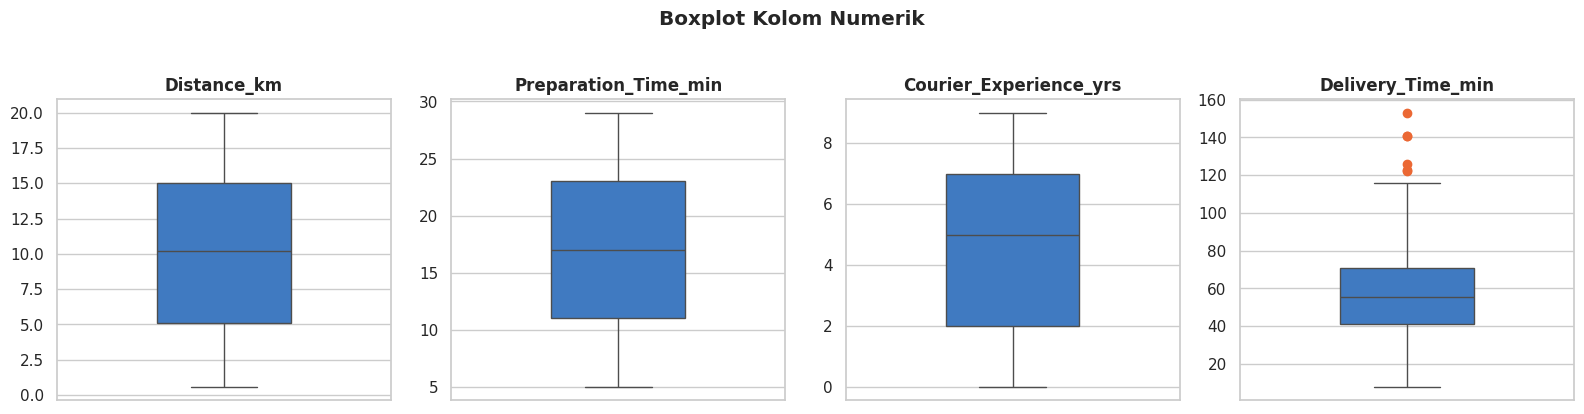

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, kolom in zip(axes, kolom_numerik):
    sns.boxplot(y=df_clean[kolom], ax=ax, color=WARNA_UTAMA, width=0.4,
                flierprops={'marker': 'o', 'markerfacecolor': WARNA_SOROT, 'markeredgecolor': WARNA_SOROT})
    ax.set_title(kolom)
    ax.set_ylabel('')
plt.suptitle('Boxplot Kolom Numerik', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

In [12]:
# Melihat detail 6 order yang terdeteksi outlier pada Delivery_Time_min
q1, q3 = df_clean['Delivery_Time_min'].quantile([0.25, 0.75])
batas_atas_target = q3 + 1.5 * (q3 - q1)
outlier_target = df_clean[df_clean['Delivery_Time_min'] > batas_atas_target]
outlier_target.sort_values('Delivery_Time_min', ascending=False)

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min
379,814,18.46,Clear,Medium,Morning,Scooter,29,1,153
127,446,18.97,Clear,Low,Evening,Car,25,4,141
452,394,15.64,Rainy,Low,Morning,Bike,20,4,141
784,385,14.83,Rainy,Low,Morning,Car,19,4,126
29,948,18.05,Clear,Medium,Evening,Scooter,10,7,123
924,428,17.81,Windy,High,Evening,Bike,21,4,122


Hanya kolom `Delivery_Time_min` yang punya outlier, yaitu **6 order** dengan waktu antar di atas 116 menit (paling lama 153 menit). Kolom lain tidak punya outlier.

**Keputusan: outlier tetap dipertahankan.** Alasannya:
- Keenam order ini semuanya punya jarak jauh (14,8 sampai 19 km), jadi waktu yang lama masih masuk akal dan bukan salah input.
- Order yang sangat lama justru adalah kasus yang ingin kita pahami. Kalau dibuang, kita kehilangan contoh keterlambatan yang paling parah.
- Jumlahnya hanya 0,6% dari data, sehingga tidak banyak mengubah rata-rata.

Supaya tetap bisa dibedakan, dibuat kolom penanda `Is_Outlier`.

### 2.9 Transformasi Data dan Feature Engineering
Beberapa kolom baru dibuat supaya analisis dan dashboard lebih mudah dibaca:

| Kolom Baru | Cara Pembuatan | Kegunaan |
|---|---|---|
| `Travel_Time_min` | `Delivery_Time_min` dikurangi `Preparation_Time_min` | Melihat berapa lama waktu yang habis di jalan |
| `Distance_Group` | Jarak dikelompokkan: 0-5, 5-10, 10-15, 15-20 km | Membandingkan order dekat dan jauh |
| `Prep_Group` | Waktu persiapan: Fast (5-10), Medium (11-20), Slow (21-29 menit) | Membandingkan restoran cepat dan lambat |
| `Experience_Level` | Pengalaman kurir: Junior (0-2), Mid (3-5), Senior (6-9 tahun) | Membandingkan kurir baru dan senior |
| `Is_Late` | 1 jika waktu antar > 60 menit, 0 jika tidak | Menghitung persentase order terlambat |
| `Delivery_Status` | Label teks dari `Is_Late`: Late atau On Time | Dipakai untuk filter di dashboard |
| `Is_Outlier` | 1 jika waktu antar > batas atas IQR | Penanda order ekstrem |

In [13]:
df_clean['Travel_Time_min'] = df_clean['Delivery_Time_min'] - df_clean['Preparation_Time_min']

df_clean['Distance_Group'] = pd.cut(df_clean['Distance_km'], bins=[0, 5, 10, 15, 20],
                                    labels=['0-5 km', '5-10 km', '10-15 km', '15-20 km'],
                                    include_lowest=True)

df_clean['Prep_Group'] = pd.cut(df_clean['Preparation_Time_min'], bins=[0, 10, 20, 30],
                                labels=['Fast (5-10 min)', 'Medium (11-20 min)', 'Slow (21-29 min)'])

df_clean['Experience_Level'] = pd.cut(df_clean['Courier_Experience_yrs'], bins=[-1, 2, 5, 9],
                                      labels=['Junior (0-2 yrs)', 'Mid (3-5 yrs)', 'Senior (6-9 yrs)'])

df_clean['Is_Late'] = (df_clean['Delivery_Time_min'] > 60).astype(int)
df_clean['Delivery_Status'] = np.where(df_clean['Is_Late'] == 1, 'Late', 'On Time')
df_clean['Is_Outlier'] = (df_clean['Delivery_Time_min'] > batas_atas_target).astype(int)

df_clean.head()

,Order_ID,Distance_km,Weather,Traffic_Level,Time_of_Day,Vehicle_Type,Preparation_Time_min,Courier_Experience_yrs,Delivery_Time_min,Travel_Time_min,Distance_Group,Prep_Group,Experience_Level,Is_Late,Delivery_Status,Is_Outlier
0,522,7.93,Windy,Low,Afternoon,Scooter,12,1,43,31,5-10 km,Medium (11-20 min),Junior (0-2 yrs),0,On Time,0
1,738,16.42,Clear,Medium,Evening,Bike,20,2,84,64,15-20 km,Medium (11-20 min),Junior (0-2 yrs),1,Late,0
2,741,9.52,Foggy,Low,Night,Scooter,28,1,59,31,5-10 km,Slow (21-29 min),Junior (0-2 yrs),0,On Time,0
3,661,7.44,Rainy,Medium,Afternoon,Scooter,5,1,37,32,5-10 km,Fast (5-10 min),Junior (0-2 yrs),0,On Time,0
4,412,19.03,Clear,Low,Morning,Bike,16,5,68,52,15-20 km,Medium (11-20 min),Mid (3-5 yrs),1,Late,0


In [14]:
# Cek jumlah data di tiap kelompok baru
for kolom in ['Distance_Group', 'Prep_Group', 'Experience_Level', 'Delivery_Status']:
    print(df_clean[kolom].value_counts(sort=False).to_string(), '\n')

Distance_Group
0-5 km      248
5-10 km     241
10-15 km    260
15-20 km    251 

Prep_Group
Fast (5-10 min)       246
Medium (11-20 min)    391
Slow (21-29 min)      363 

Experience_Level
Junior (0-2 yrs)    297
Mid (3-5 yrs)       294
Senior (6-9 yrs)    409 

Delivery_Status
On Time    585
Late       415 



### 2.10 Menyimpan Data Bersih
Data yang sudah bersih disimpan ke file CSV baru. File inilah yang nanti dipakai untuk membuat dashboard di Power BI.

In [15]:
df_clean.to_csv('Food_Delivery_Clean.csv', index=False)
print('Data bersih tersimpan:', df_clean.shape[0], 'baris,', df_clean.shape[1], 'kolom')

# Untuk download file ke laptop, hapus tanda # di dua baris bawah lalu jalankan (khusus Colab)
# from google.colab import files
# files.download('Food_Delivery_Clean.csv')

Data bersih tersimpan: 1000 baris, 16 kolom


**Ringkasan preprocessing:**
1. Missing value di 4 kolom (masing-masing 3%) diisi dengan modus untuk kolom kategorikal dan median untuk pengalaman kurir.
2. Tidak ada data duplikat.
3. Tipe data disesuaikan: pengalaman kurir menjadi integer, kolom kategorikal menjadi category berurutan.
4. Validasi logika: semua data masuk akal.
5. Ada 6 outlier pada waktu antar, dipertahankan karena wajar (jarak jauh) dan diberi penanda.
6. Dibuat 7 kolom baru untuk analisis dan dashboard.

## Tahap 3. Exploratory Data Analysis (EDA)

### 3.1 Statistik Deskriptif

In [16]:
deskriptif = df_clean[kolom_numerik].describe().T
deskriptif['median'] = df_clean[kolom_numerik].median()
deskriptif['skewness'] = df_clean[kolom_numerik].skew()
deskriptif = deskriptif[['count', 'mean', 'median', 'std', 'min', '25%', '75%', 'max', 'skewness']]
deskriptif.round(2)

,count,mean,median,std,min,25%,75%,max,skewness
Distance_km,1000.0,10.06,10.19,5.70,0.59,5.11,15.02,19.99,0.04
Preparation_Time_min,1000.0,16.98,17.00,7.20,5.00,11.00,23.00,29.00,0.03
Courier_Experience_yrs,1000.0,4.59,5.00,2.87,0.00,2.00,7.00,9.00,-0.04
Delivery_Time_min,1000.0,56.73,55.50,22.07,8.00,41.00,71.00,153.00,0.51


In [17]:
# Ringkasan kolom kategorikal: jumlah dan persentase tiap kategori
for kolom in kolom_kategori:
    ringkas = pd.DataFrame({
        'Jumlah': df_clean[kolom].value_counts(sort=False),
        'Persentase (%)': (df_clean[kolom].value_counts(normalize=True, sort=False) * 100).round(1)
    })
    print(f'--- {kolom} ---')
    print(ringkas.to_string(), '\n')

--- Weather ---
         Jumlah  Persentase (%)
Weather                        
Clear       500            50.0
Windy        96             9.6
Foggy       103            10.3
Rainy       204            20.4
Snowy        97             9.7 

--- Traffic_Level ---
               Jumlah  Persentase (%)
Traffic_Level                        
Low               383            38.3
Medium            420            42.0
High              197            19.7 

--- Time_of_Day ---
             Jumlah  Persentase (%)
Time_of_Day                        
Morning         338            33.8
Afternoon       284            28.4
Evening         293            29.3
Night            85             8.5 

--- Vehicle_Type ---
              Jumlah  Persentase (%)
Vehicle_Type                        
Bike             503            50.3
Scooter          302            30.2
Car              195            19.5 



**Insight:**
- Rata-rata waktu pengiriman adalah **56,7 menit** dengan median **55,5 menit**. Nilainya bervariasi cukup lebar, dari 8 menit sampai 153 menit.
- Skewness waktu antar sekitar 0,5, artinya distribusinya sedikit condong ke kanan: sebagian besar order selesai di kisaran 40 sampai 70 menit, tapi ada beberapa order yang sangat lama.
- Jarak pengiriman tersebar merata dari 0,6 sampai 20 km (rata-rata 10 km). Waktu persiapan berkisar 5 sampai 29 menit.
- Mayoritas pengiriman terjadi saat cuaca cerah (50%), traffic rendah sampai sedang (80%), dan menggunakan motor jenis Bike (50%). Pengiriman malam hari paling sedikit (8,5%).

### 3.2 Distribusi Variabel Numerik

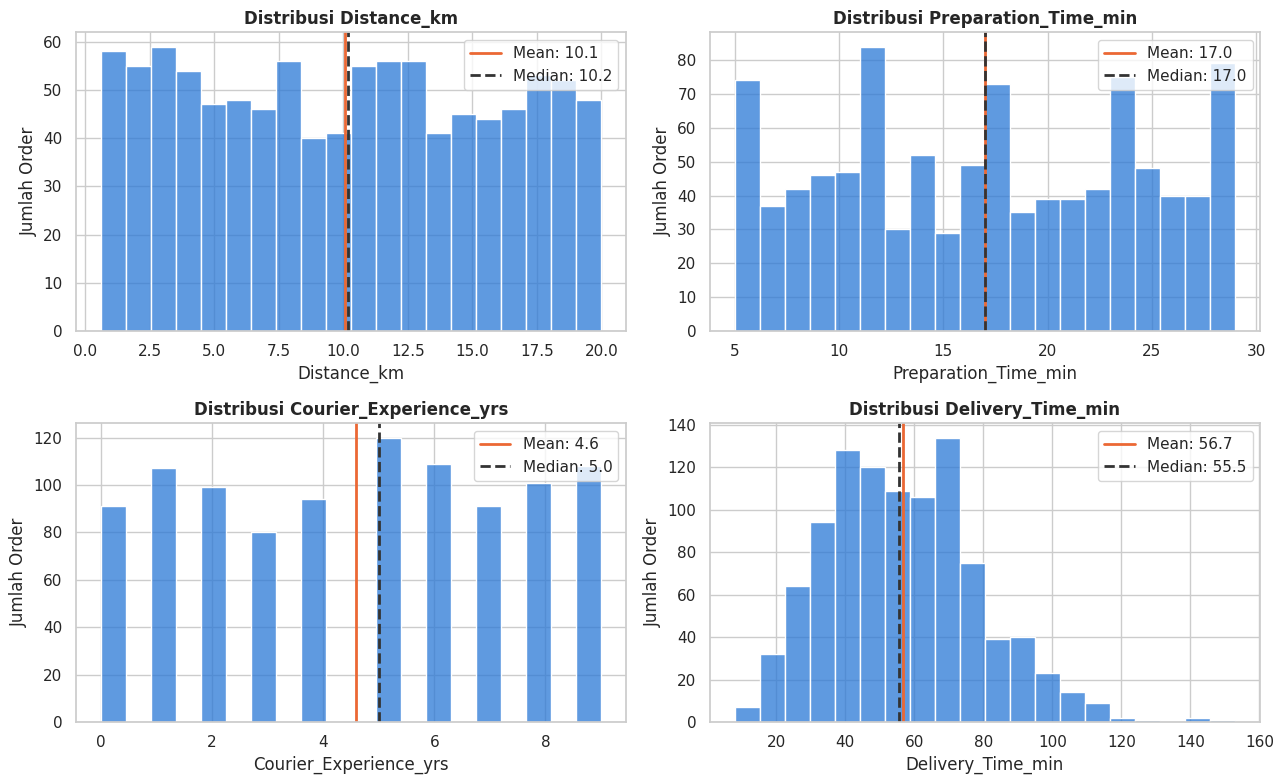

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, kolom in zip(axes.flatten(), kolom_numerik):
    sns.histplot(df_clean[kolom], bins=20, ax=ax, color=WARNA_UTAMA, edgecolor='white')
    ax.axvline(df_clean[kolom].mean(), color=WARNA_SOROT, linewidth=2, label=f'Mean: {df_clean[kolom].mean():.1f}')
    ax.axvline(df_clean[kolom].median(), color='#333333', linewidth=2, linestyle='--',
               label=f'Median: {df_clean[kolom].median():.1f}')
    ax.set_title(f'Distribusi {kolom}')
    ax.set_ylabel('Jumlah Order')
    ax.legend()
plt.tight_layout()
plt.show()

**Insight:**
- `Distance_km` dan `Preparation_Time_min` tersebar cukup merata (bentuk histogram hampir datar), jadi setiap rentang jarak dan waktu persiapan punya jumlah order yang mirip. Ini bagus karena perbandingan antar kelompok jadi adil.
- `Courier_Experience_yrs` juga merata dari 0 sampai 9 tahun. Batang di angka 5 terlihat sedikit lebih tinggi karena pengisian missing value dengan median.
- `Delivery_Time_min` berbentuk hampir normal dengan ekor di sisi kanan. Puncaknya ada di sekitar 40 sampai 70 menit.

### 3.3 Distribusi Variabel Kategorikal

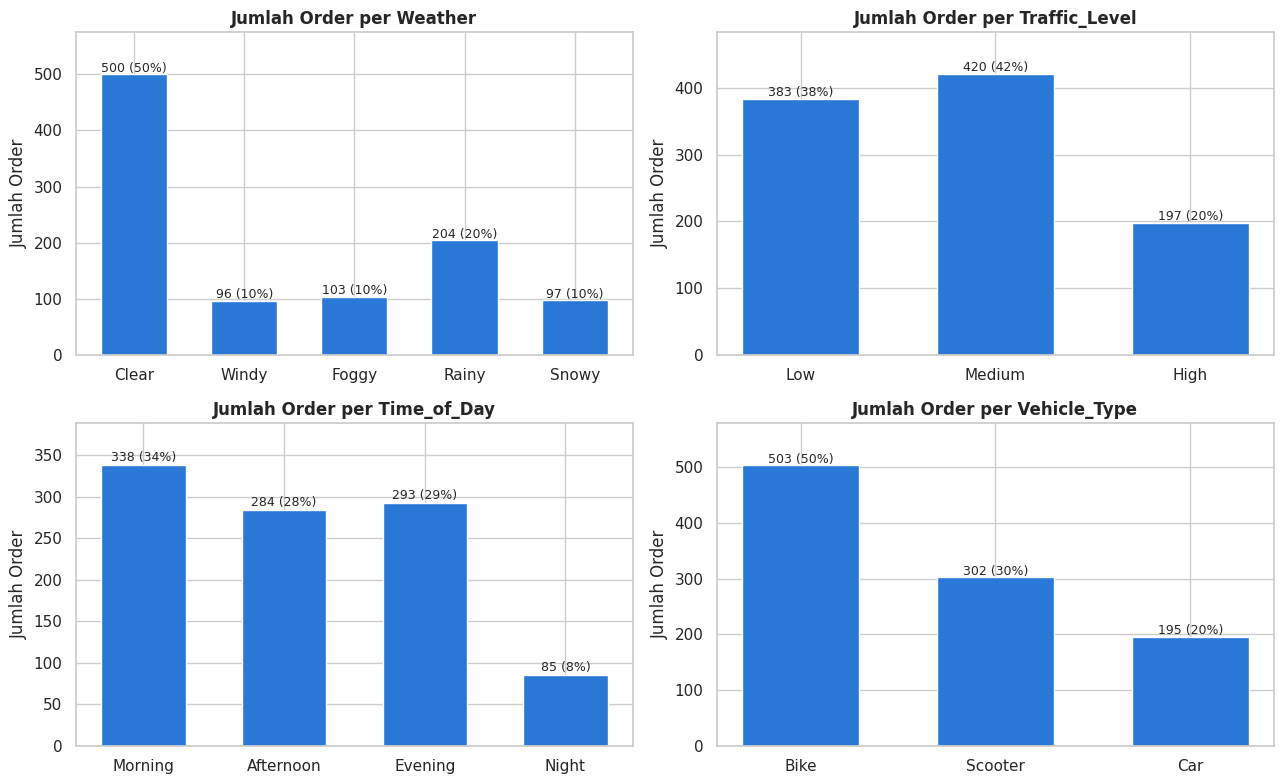

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, kolom in zip(axes.flatten(), kolom_kategori):
    jumlah = df_clean[kolom].value_counts(sort=False)
    bars = ax.bar(jumlah.index.astype(str), jumlah.values, color=WARNA_UTAMA, width=0.6)
    for bar, nilai in zip(bars, jumlah.values):
        ax.text(bar.get_x() + bar.get_width() / 2, nilai + 5, f'{nilai} ({nilai / len(df_clean):.0%})',
                ha='center', fontsize=9)
    ax.set_title(f'Jumlah Order per {kolom}')
    ax.set_ylabel('Jumlah Order')
    ax.set_ylim(0, jumlah.max() * 1.15)
plt.tight_layout()
plt.show()

### 3.4 Distribusi Variabel Target dan Tingkat Keterlambatan

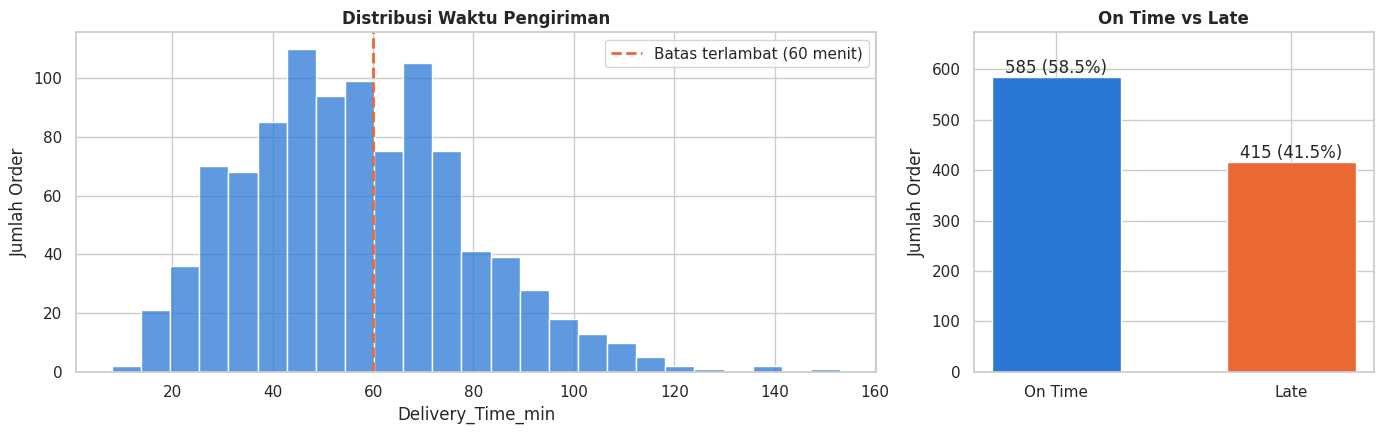

Order terlambat (> 60 menit): 415 dari 1000 order (41.5%)


In [20]:
jumlah_telat = df_clean['Is_Late'].sum()
persen_telat = df_clean['Is_Late'].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={'width_ratios': [2, 1]})

sns.histplot(df_clean['Delivery_Time_min'], bins=25, ax=axes[0], color=WARNA_UTAMA, edgecolor='white')
axes[0].axvline(60, color=WARNA_SOROT, linewidth=2, linestyle='--', label='Batas terlambat (60 menit)')
axes[0].set_title('Distribusi Waktu Pengiriman')
axes[0].set_xlabel('Delivery_Time_min')
axes[0].set_ylabel('Jumlah Order')
axes[0].legend()

status = df_clean['Delivery_Status'].value_counts().reindex(['On Time', 'Late'])
bars = axes[1].bar(status.index, status.values, color=[WARNA_UTAMA, WARNA_SOROT], width=0.55)
for bar, nilai in zip(bars, status.values):
    axes[1].text(bar.get_x() + bar.get_width() / 2, nilai + 8, f'{nilai} ({nilai / len(df_clean):.1%})', ha='center')
axes[1].set_title('On Time vs Late')
axes[1].set_ylabel('Jumlah Order')
axes[1].set_ylim(0, status.max() * 1.15)

plt.tight_layout()
plt.show()

print(f'Order terlambat (> 60 menit): {jumlah_telat} dari {len(df_clean)} order ({persen_telat:.1%})')

**Insight:** sebanyak **415 order (41,5%) terlambat**, artinya hampir setengah dari seluruh pengiriman memakan waktu lebih dari 1 jam. Ini angka yang cukup tinggi dan menjadi masalah utama yang perlu dicari penyebabnya.

### 3.5 Hubungan Antar Variabel Numerik

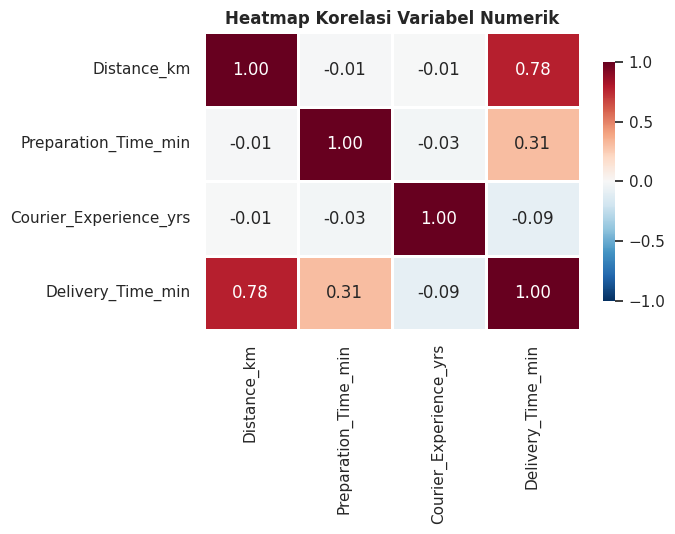

Korelasi setiap variabel terhadap Delivery_Time_min:
Distance_km               0.781
Preparation_Time_min      0.307
Courier_Experience_yrs   -0.089
Name: Delivery_Time_min, dtype: float64


In [21]:
korelasi = df_clean[kolom_numerik].corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(korelasi, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor='white', cbar_kws={'shrink': 0.8})
plt.title('Heatmap Korelasi Variabel Numerik')
plt.tight_layout()
plt.show()

print('Korelasi setiap variabel terhadap Delivery_Time_min:')
print(korelasi['Delivery_Time_min'].drop('Delivery_Time_min').sort_values(ascending=False).round(3))

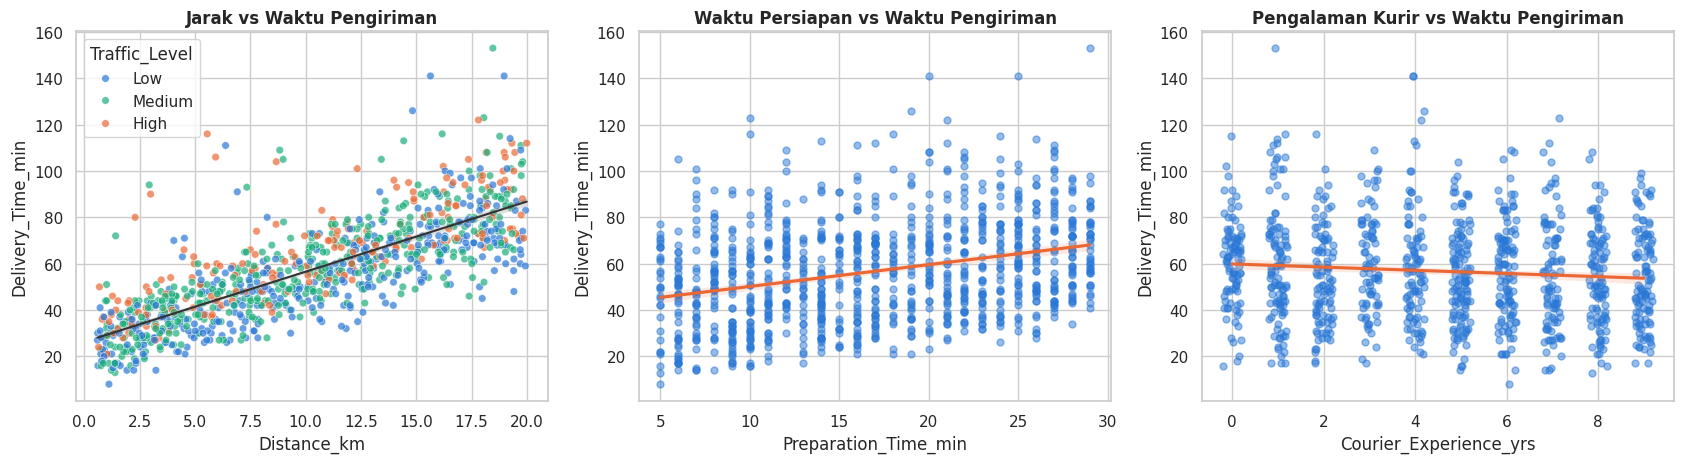

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

warna_traffic = {'Low': '#2a78d6', 'Medium': '#1baf7a', 'High': '#eb6834'}
sns.scatterplot(data=df_clean, x='Distance_km', y='Delivery_Time_min', hue='Traffic_Level',
                palette=warna_traffic, alpha=0.7, s=30, ax=axes[0])
sns.regplot(data=df_clean, x='Distance_km', y='Delivery_Time_min', scatter=False, ax=axes[0],
            color='#333333', line_kws={'linewidth': 1.5})
axes[0].set_title('Jarak vs Waktu Pengiriman')

sns.regplot(data=df_clean, x='Preparation_Time_min', y='Delivery_Time_min', ax=axes[1],
            scatter_kws={'alpha': 0.5, 's': 25, 'color': WARNA_UTAMA}, line_kws={'color': WARNA_SOROT})
axes[1].set_title('Waktu Persiapan vs Waktu Pengiriman')

sns.regplot(data=df_clean, x='Courier_Experience_yrs', y='Delivery_Time_min', ax=axes[2], x_jitter=0.2,
            scatter_kws={'alpha': 0.5, 's': 25, 'color': WARNA_UTAMA}, line_kws={'color': WARNA_SOROT})
axes[2].set_title('Pengalaman Kurir vs Waktu Pengiriman')

plt.tight_layout()
plt.show()

**Insight:**
- **Jarak adalah faktor dengan hubungan paling kuat** terhadap waktu pengiriman (korelasi **0,78**, positif kuat). Semakin jauh jarak, semakin lama pengiriman. Di scatter plot terlihat titik oranye (traffic High) cenderung berada di atas garis, artinya pada jarak yang sama, traffic tinggi membuat pengiriman lebih lama.
- **Waktu persiapan** punya korelasi positif sedang (**0,31**). Restoran yang lama menyiapkan makanan ikut memperlambat pengiriman.
- **Pengalaman kurir** hampir tidak berhubungan (korelasi **-0,09**, sangat lemah). Arahnya negatif, jadi kurir yang lebih berpengalaman sedikit lebih cepat, tapi pengaruhnya kecil.
- Antar variabel input (jarak, persiapan, pengalaman) tidak saling berkorelasi, sehingga pengaruh masing-masing bisa dilihat secara terpisah.

### 3.6 Perbandingan Waktu Pengiriman per Kategori

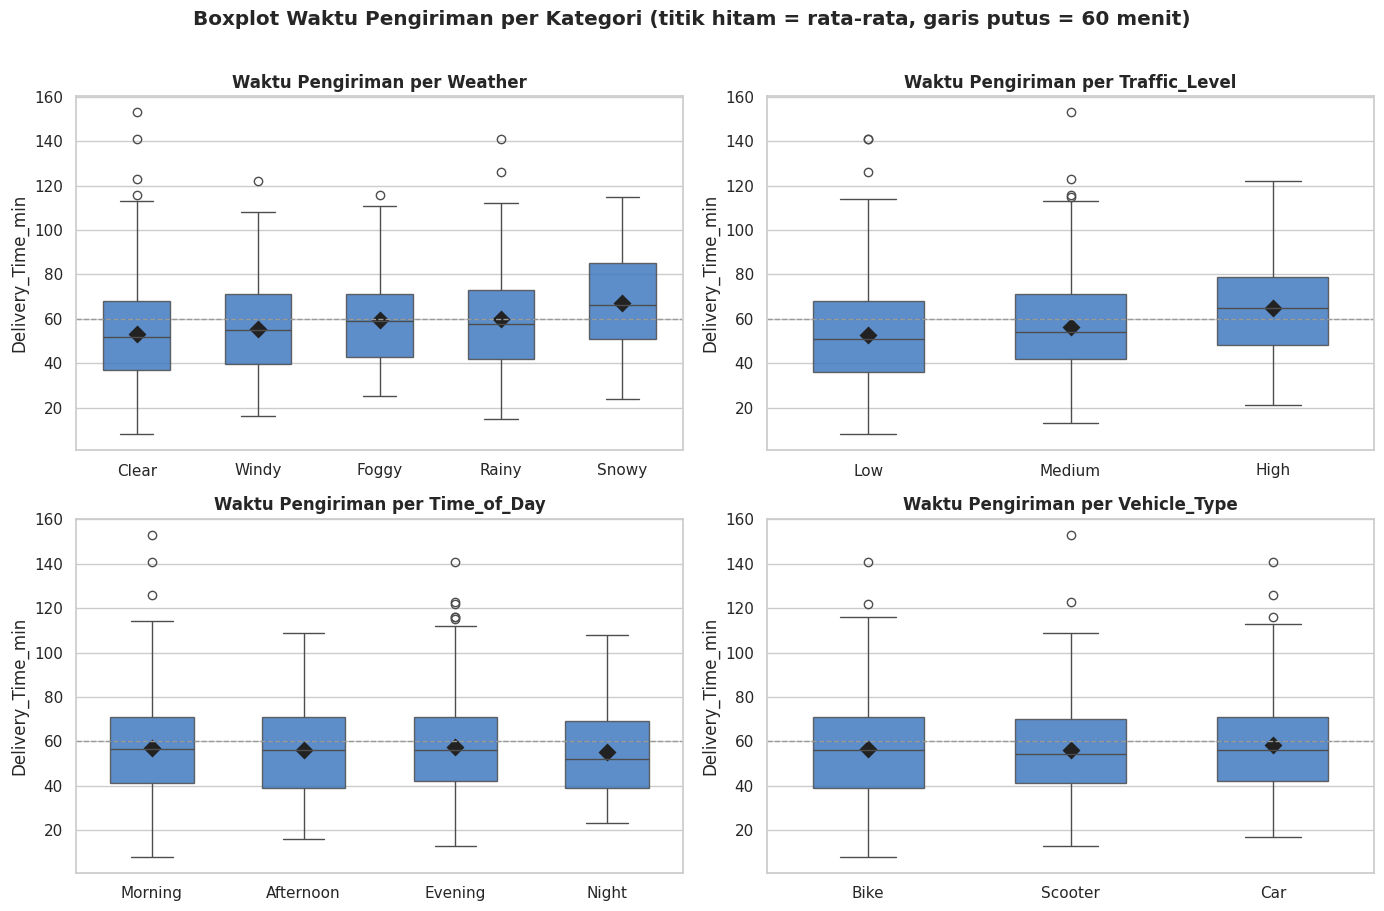

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, kolom in zip(axes.flatten(), kolom_kategori):
    sns.boxplot(data=df_clean, x=kolom, y='Delivery_Time_min', color=WARNA_UTAMA, ax=ax, width=0.55,
                boxprops={'alpha': 0.85})
    sns.pointplot(data=df_clean, x=kolom, y='Delivery_Time_min', estimator='mean', errorbar=None,
                  color='#222222', markers='D', linestyles='none', ax=ax)
    ax.axhline(60, color=WARNA_ABU, linestyle='--', linewidth=1)
    ax.set_title(f'Waktu Pengiriman per {kolom}')
    ax.set_xlabel('')
    ax.set_ylabel('Delivery_Time_min')
plt.suptitle('Boxplot Waktu Pengiriman per Kategori (titik hitam = rata-rata, garis putus = 60 menit)',
             fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [24]:
# Tabel ringkasan per kategori: jumlah order, rata-rata, median, dan persentase terlambat
def ringkasan_per(kolom):
    tabel = df_clean.groupby(kolom, observed=True).agg(
        Jumlah_Order=('Order_ID', 'count'),
        Rata2_Menit=('Delivery_Time_min', 'mean'),
        Median_Menit=('Delivery_Time_min', 'median'),
        Persen_Terlambat=('Is_Late', 'mean')
    )
    tabel['Persen_Terlambat'] = (tabel['Persen_Terlambat'] * 100)
    return tabel.round(1)

for kolom in kolom_kategori:
    print(f'--- {kolom} ---')
    print(ringkasan_per(kolom).to_string(), '\n')

--- Weather ---
         Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Weather                                                           
Clear             500         53.2          52.0              35.6
Windy              96         55.5          55.0              43.8
Foggy             103         59.5          59.0              47.6
Rainy             204         59.8          57.5              43.1
Snowy              97         67.1          66.0              59.8 

--- Traffic_Level ---
               Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Traffic_Level                                                           
Low                     383         52.9          51.0              36.3
Medium                  420         56.5          54.0              40.2
High                    197         64.8          65.0              54.3 

--- Time_of_Day ---
             Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Time_of_Day                      

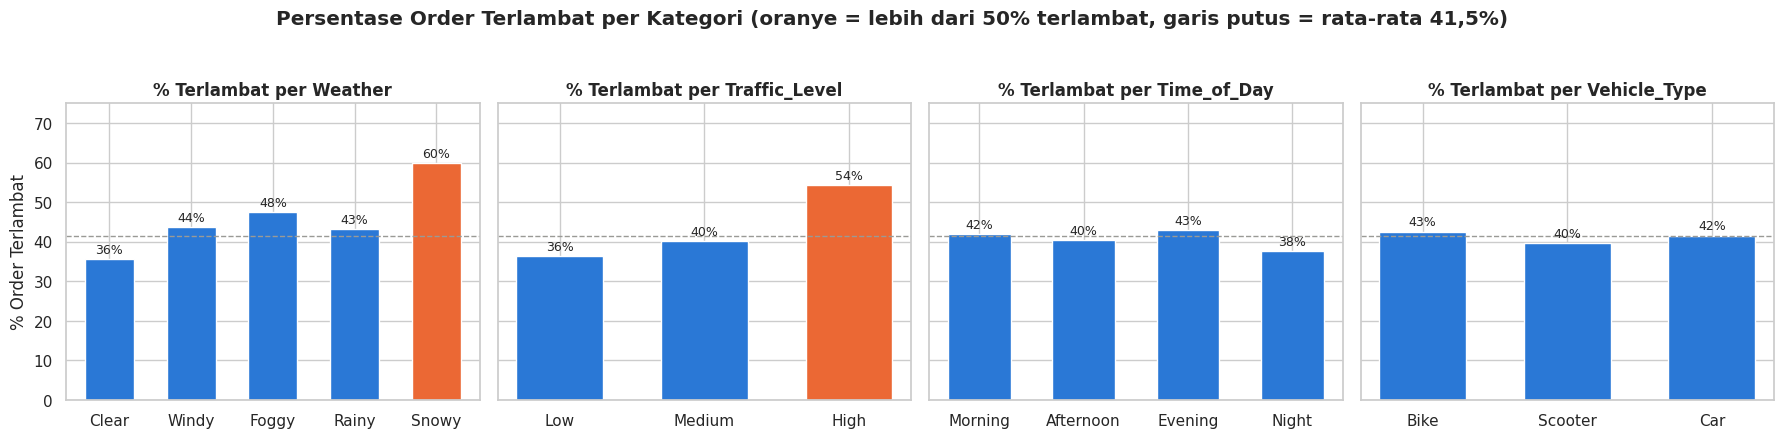

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, kolom in zip(axes, kolom_kategori):
    persen = df_clean.groupby(kolom, observed=True)['Is_Late'].mean() * 100
    warna = [WARNA_SOROT if nilai > 50 else WARNA_UTAMA for nilai in persen.values]
    bars = ax.bar(persen.index.astype(str), persen.values, color=warna, width=0.6)
    for bar, nilai in zip(bars, persen.values):
        ax.text(bar.get_x() + bar.get_width() / 2, nilai + 1.5, f'{nilai:.0f}%', ha='center', fontsize=9)
    ax.axhline(df_clean['Is_Late'].mean() * 100, color=WARNA_ABU, linestyle='--', linewidth=1)
    ax.set_title(f'% Terlambat per {kolom}')
    ax.set_ylim(0, 75)
axes[0].set_ylabel('% Order Terlambat')
plt.suptitle('Persentase Order Terlambat per Kategori (oranye = lebih dari 50% terlambat, garis putus = rata-rata 41,5%)',
             fontweight='bold', y=1.04)
plt.tight_layout()
plt.show()

**Insight:**
- **Traffic:** semakin padat lalu lintas, semakin lama pengiriman. Traffic **High** rata-rata **64,8 menit** dengan **54% order terlambat**, sedangkan traffic **Low** hanya **52,9 menit** (36% terlambat). Selisihnya sekitar 12 menit.
- **Cuaca:** cuaca **Snowy** paling lambat (rata-rata **67,1 menit**, **60% terlambat**), disusul Rainy (59,8 menit) dan Foggy (59,5 menit). Cuaca Clear paling cepat (53,2 menit). Windy hampir tidak beda jauh dengan Clear.
- Hanya dua kategori yang order terlambatnya lebih dari separuh: **Snowy** dan **traffic High**.
- **Waktu dalam sehari:** rata-rata waktu antar di pagi, siang, sore, dan malam **hampir sama** (55 sampai 57,5 menit). Artinya jam pengiriman tidak terlalu menentukan lamanya pengiriman.
- **Jenis kendaraan:** Bike, Scooter, dan Car juga **hampir sama** (56 sampai 58 menit). Menariknya, mobil tidak lebih cepat dari motor.

### 3.7 Perbandingan per Kelompok (Hasil Feature Engineering)

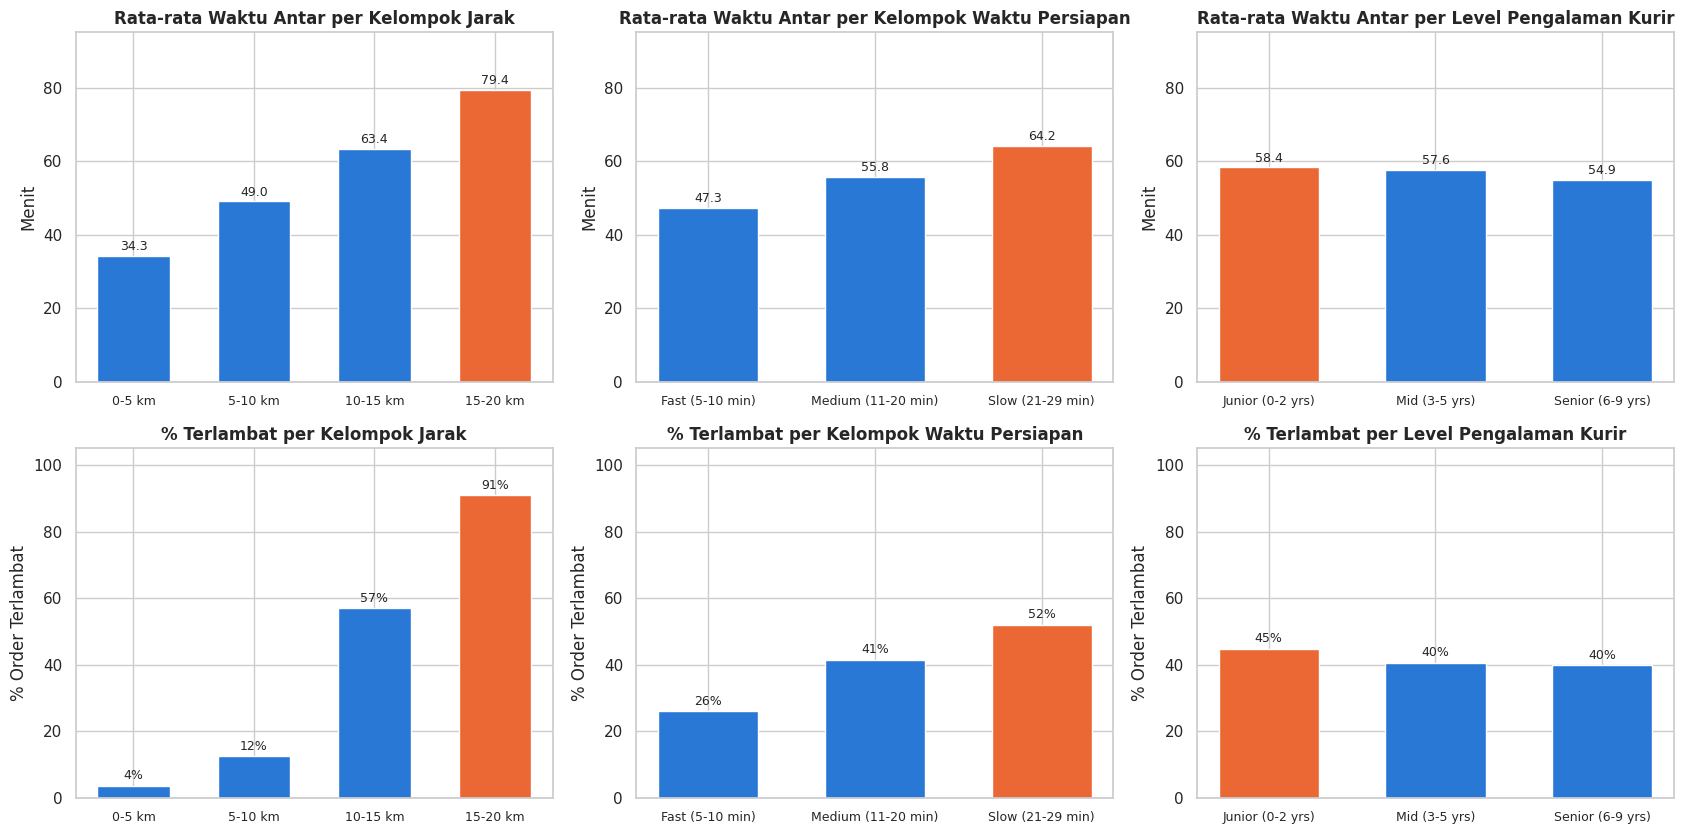

--- Distance_Group ---
                Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Distance_Group                                                           
0-5 km                   248         34.3          34.0               3.6
5-10 km                  241         49.0          48.0              12.4
10-15 km                 260         63.4          63.0              56.9
15-20 km                 251         79.4          77.0              90.8 

--- Prep_Group ---
                    Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Prep_Group                                                                   
Fast (5-10 min)              246         47.3          47.0              26.0
Medium (11-20 min)           391         55.8          55.0              41.4
Slow (21-29 min)             363         64.2          62.0              52.1 

--- Experience_Level ---
                  Jumlah_Order  Rata2_Menit  Median_Menit  Persen_Terlambat
Experience_Level   

In [26]:
kolom_grup = ['Distance_Group', 'Prep_Group', 'Experience_Level']
judul_grup = ['Kelompok Jarak', 'Kelompok Waktu Persiapan', 'Level Pengalaman Kurir']

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for i, (kolom, judul) in enumerate(zip(kolom_grup, judul_grup)):
    ringkas = df_clean.groupby(kolom, observed=True).agg(rata2=('Delivery_Time_min', 'mean'),
                                                        telat=('Is_Late', 'mean'))
    label = ringkas.index.astype(str)

    warna = [WARNA_SOROT if v == ringkas['rata2'].max() else WARNA_UTAMA for v in ringkas['rata2']]
    bars = axes[0, i].bar(label, ringkas['rata2'], color=warna, width=0.6)
    for bar, nilai in zip(bars, ringkas['rata2']):
        axes[0, i].text(bar.get_x() + bar.get_width() / 2, nilai + 1.5, f'{nilai:.1f}', ha='center', fontsize=9)
    axes[0, i].set_title(f'Rata-rata Waktu Antar per {judul}')
    axes[0, i].set_ylabel('Menit')
    axes[0, i].set_ylim(0, 95)
    axes[0, i].tick_params(axis='x', labelsize=9)

    warna = [WARNA_SOROT if v == ringkas['telat'].max() else WARNA_UTAMA for v in ringkas['telat']]
    bars = axes[1, i].bar(label, ringkas['telat'] * 100, color=warna, width=0.6)
    for bar, nilai in zip(bars, ringkas['telat'] * 100):
        axes[1, i].text(bar.get_x() + bar.get_width() / 2, nilai + 2, f'{nilai:.0f}%', ha='center', fontsize=9)
    axes[1, i].set_title(f'% Terlambat per {judul}')
    axes[1, i].set_ylabel('% Order Terlambat')
    axes[1, i].set_ylim(0, 105)
    axes[1, i].tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.show()

for kolom in kolom_grup:
    print(f'--- {kolom} ---')
    print(ringkasan_per(kolom).to_string(), '\n')

In [27]:
# Dari seluruh order yang terlambat, berapa persen yang jaraknya lebih dari 10 km?
telat = df_clean[df_clean['Is_Late'] == 1]
porsi_jauh = (telat['Distance_km'] > 10).mean()
print(f'Order terlambat dengan jarak > 10 km: {(telat["Distance_km"] > 10).sum()} dari {len(telat)} ({porsi_jauh:.1%})')

# Rata-rata porsi waktu persiapan terhadap total waktu antar
porsi_persiapan = (df_clean['Preparation_Time_min'] / df_clean['Delivery_Time_min']).mean()
print(f'Rata-rata porsi waktu persiapan terhadap total waktu antar: {porsi_persiapan:.1%}')

Order terlambat dengan jarak > 10 km: 376 dari 415 (90.6%)
Rata-rata porsi waktu persiapan terhadap total waktu antar: 33.3%


**Insight:**
- **Jarak sangat menentukan.** Rata-rata waktu antar naik terus dari **34,3 menit** (0-5 km) menjadi **79,4 menit** (15-20 km), lebih dari 2 kali lipat. Persentase terlambat melonjak dari hanya **4%** di jarak 0-5 km menjadi **91%** di jarak 15-20 km.
- **90,6% order yang terlambat adalah order dengan jarak lebih dari 10 km.** Jadi masalah keterlambatan sebagian besar berasal dari order jarak jauh.
- **Waktu persiapan juga berpengaruh jelas.** Restoran dengan persiapan lambat (21-29 menit) membuat rata-rata waktu antar **64,2 menit** dengan **52% terlambat**, dibanding persiapan cepat (5-10 menit) yang hanya **47,3 menit** dengan **26% terlambat**. Rata-rata, waktu persiapan memakan sekitar **sepertiga (33%)** dari total waktu pengiriman.
- **Pengalaman kurir pengaruhnya kecil.** Kurir senior memang sedikit lebih cepat (54,9 menit) dibanding junior (58,4 menit), tapi selisihnya hanya sekitar 3,5 menit.

### 3.8 Analisis Kombinasi Faktor
Setelah melihat faktor satu per satu, sekarang dilihat bagaimana jika beberapa faktor terjadi bersamaan.

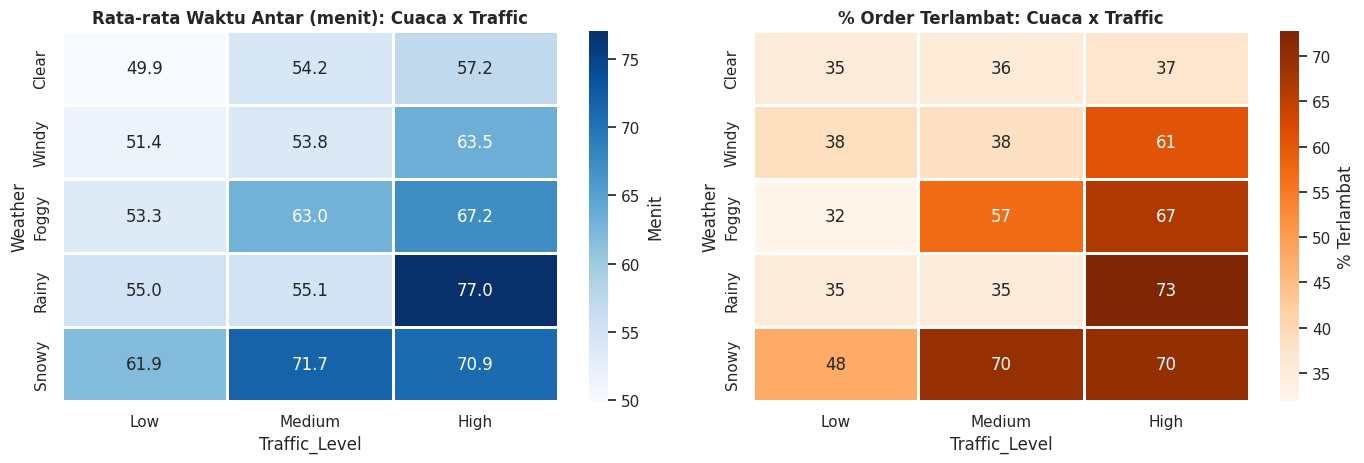

Jumlah order di tiap kombinasi:
Traffic_Level  Low  Medium  High
Weather                         
Clear          186     225    89
Windy           26      47    23
Foggy           47      35    21
Rainy           80      80    44
Snowy           44      33    20


In [28]:
pivot_rata2 = pd.pivot_table(df_clean, values='Delivery_Time_min', index='Weather',
                             columns='Traffic_Level', aggfunc='mean', observed=True)
pivot_telat = pd.pivot_table(df_clean, values='Is_Late', index='Weather',
                             columns='Traffic_Level', aggfunc='mean', observed=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.heatmap(pivot_rata2, annot=True, fmt='.1f', cmap='Blues', linewidths=1, linecolor='white',
            ax=axes[0], cbar_kws={'label': 'Menit'})
axes[0].set_title('Rata-rata Waktu Antar (menit): Cuaca x Traffic')
sns.heatmap(pivot_telat, annot=True, fmt='.0f', cmap='Oranges', linewidths=1, linecolor='white',
            ax=axes[1], cbar_kws={'label': '% Terlambat'})
axes[1].set_title('% Order Terlambat: Cuaca x Traffic')
plt.tight_layout()
plt.show()

print('Jumlah order di tiap kombinasi:')
print(pd.crosstab(df_clean['Weather'], df_clean['Traffic_Level']))

In [29]:
cuaca_buruk = df_clean['Weather'] != 'Clear'
traffic_tinggi = df_clean['Traffic_Level'] == 'High'
cerah_lancar = (df_clean['Weather'] == 'Clear') & (df_clean['Traffic_Level'] == 'Low')

def info_segmen(nama, filter_data):
    data = df_clean[filter_data]
    print(f'{nama:<40} {len(data):>4} order | rata-rata {data["Delivery_Time_min"].mean():5.1f} menit | '
          f'terlambat {data["Is_Late"].mean():.1%}')

info_segmen('Cuaca buruk + traffic High', cuaca_buruk & traffic_tinggi)
info_segmen('Cuaca Clear + traffic Low', cerah_lancar)
info_segmen('Jarak > 15 km + persiapan > 20 menit',
            (df_clean['Distance_km'] > 15) & (df_clean['Preparation_Time_min'] > 20))
info_segmen('Jarak <= 5 km + persiapan <= 10 menit',
            (df_clean['Distance_km'] <= 5) & (df_clean['Preparation_Time_min'] <= 10))

Cuaca buruk + traffic High                108 order | rata-rata  71.1 menit | terlambat 68.5%
Cuaca Clear + traffic Low                 186 order | rata-rata  49.9 menit | terlambat 34.9%
Jarak > 15 km + persiapan > 20 menit       98 order | rata-rata  87.2 menit | terlambat 99.0%
Jarak <= 5 km + persiapan <= 10 menit      64 order | rata-rata  25.6 menit | terlambat 4.7%


**Insight:**
- Kombinasi **cuaca buruk (selain Clear) dan traffic High** menghasilkan rata-rata **71,1 menit** dengan **68,5% order terlambat**. Bandingkan dengan kondisi ideal (Clear + Low) yang rata-ratanya **49,9 menit** dan 34,9% terlambat.
- Kombinasi terparah ada di **Rainy + High** (rata-rata 77 menit, 73% terlambat). Menariknya, hujan dengan traffic Low atau Medium hanya sekitar 55 menit, jadi hujan baru jadi masalah besar saat jalanan juga padat.
- Sebaliknya, saat cuaca **Clear**, traffic High hanya membuat 37% order terlambat (hampir sama dengan traffic Low, 35%). Jadi yang paling berbahaya adalah **cuaca buruk dan traffic padat yang terjadi bersamaan**, bukan salah satunya saja.
- Order **jarak > 15 km dengan persiapan > 20 menit** hampir pasti terlambat: **99% terlambat** dengan rata-rata 87,2 menit. Sebaliknya, order dekat (≤ 5 km) dengan persiapan cepat (≤ 10 menit) rata-rata hanya **25,6 menit** dan yang terlambat hanya 4,7%.

> Catatan: beberapa kombinasi seperti Snowy + High atau Foggy + High jumlah ordernya sedikit (sekitar 20 order), jadi angkanya perlu dibaca sebagai gambaran, bukan angka pasti.

### 3.9 Tren Waktu Antar berdasarkan Jarak dan Waktu dalam Sehari
Dataset ini tidak punya kolom tanggal, jadi tren dilihat dari dua sisi: **perubahan waktu antar seiring bertambahnya jarak**, dan **pola sepanjang hari** (pagi sampai malam).

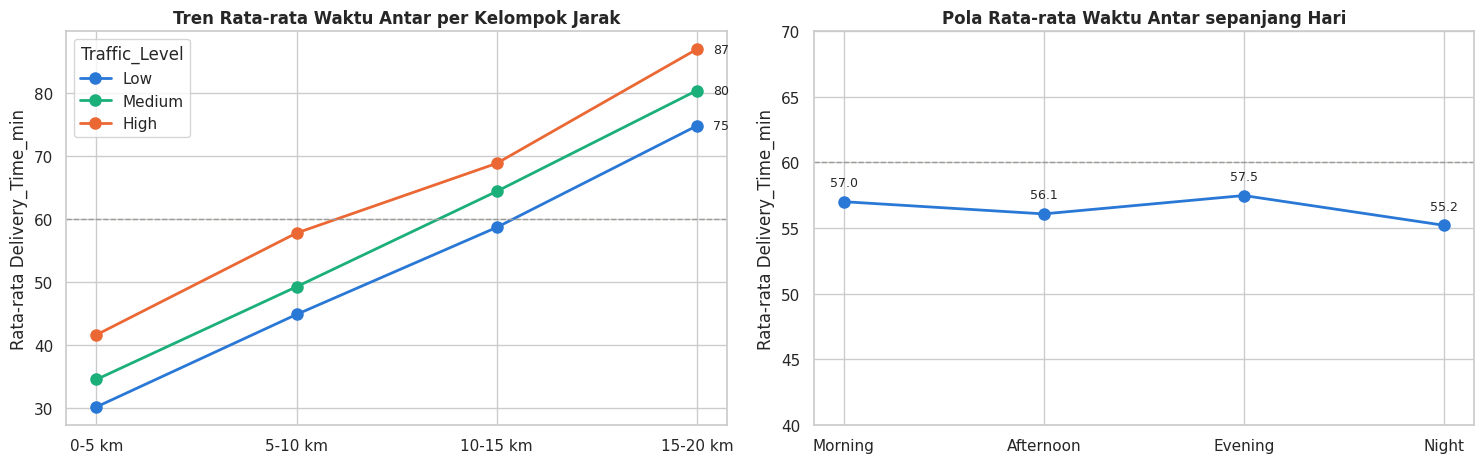

Traffic_Level    Low  Medium  High
Distance_Group                    
0-5 km          30.2    34.6  41.7
5-10 km         44.9    49.3  57.8
10-15 km        58.7    64.4  68.8
15-20 km        74.8    80.4  86.9


In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

tren_jarak = pd.pivot_table(df_clean, values='Delivery_Time_min', index='Distance_Group',
                            columns='Traffic_Level', aggfunc='mean', observed=True)
for traffic in ['Low', 'Medium', 'High']:
    axes[0].plot(tren_jarak.index.astype(str), tren_jarak[traffic], marker='o', linewidth=2,
                 markersize=8, color=warna_traffic[traffic], label=traffic)
    axes[0].text(3.08, tren_jarak[traffic].iloc[-1], f'{tren_jarak[traffic].iloc[-1]:.0f}', va='center', fontsize=9)
axes[0].axhline(60, color=WARNA_ABU, linestyle='--', linewidth=1)
axes[0].set_title('Tren Rata-rata Waktu Antar per Kelompok Jarak')
axes[0].set_ylabel('Rata-rata Delivery_Time_min')
axes[0].legend(title='Traffic_Level')

tren_waktu = df_clean.groupby('Time_of_Day', observed=True).agg(rata2=('Delivery_Time_min', 'mean'),
                                                                telat=('Is_Late', 'mean'))
axes[1].plot(tren_waktu.index.astype(str), tren_waktu['rata2'], marker='o', linewidth=2,
             markersize=8, color=WARNA_UTAMA)
for x, y in zip(tren_waktu.index.astype(str), tren_waktu['rata2']):
    axes[1].text(x, y + 1.2, f'{y:.1f}', ha='center', fontsize=9)
axes[1].axhline(60, color=WARNA_ABU, linestyle='--', linewidth=1)
axes[1].set_ylim(40, 70)
axes[1].set_title('Pola Rata-rata Waktu Antar sepanjang Hari')
axes[1].set_ylabel('Rata-rata Delivery_Time_min')

plt.tight_layout()
plt.show()

print(tren_jarak.round(1))

**Insight:**
- Waktu antar **naik secara konsisten** setiap jarak bertambah 5 km, kira-kira **+15 menit per kelompok jarak**, di semua level traffic.
- Garis traffic High selalu berada paling atas dengan selisih sekitar **10 sampai 13 menit** dari traffic Low di setiap kelompok jarak. Artinya pengaruh traffic selalu ada, baik untuk order dekat maupun jauh.
- Mulai jarak **10-15 km**, rata-rata waktu antar sudah melewati batas 60 menit (kecuali traffic Low yang masih sedikit di bawah). Di jarak 15-20 km, semua level traffic sudah jauh di atas 60 menit.
- Sepanjang hari, garisnya **hampir datar** (55 sampai 57,5 menit). Tidak ada jam tertentu yang membuat pengiriman jauh lebih lambat.

### 3.10 Uji Statistik: Faktor Mana yang Pengaruhnya Signifikan?
Untuk memastikan perbedaan yang terlihat di grafik bukan kebetulan, dilakukan uji statistik sederhana:
- **Kolom numerik:** korelasi Pearson.
- **Kolom kategorikal:** uji ANOVA (membandingkan rata-rata antar kelompok).

Jika **p-value < 0,05**, berarti faktor tersebut berpengaruh secara signifikan terhadap waktu antar.

In [31]:
hasil_uji = []

for kolom in ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs']:
    r, p = stats.pearsonr(df_clean[kolom], df_clean['Delivery_Time_min'])
    hasil_uji.append([kolom, 'Korelasi Pearson', round(r, 3), p])

for kolom in kolom_kategori:
    kelompok = [data['Delivery_Time_min'].values for _, data in df_clean.groupby(kolom, observed=True)]
    f, p = stats.f_oneway(*kelompok)
    hasil_uji.append([kolom, 'ANOVA', round(f, 2), p])

tabel_uji = pd.DataFrame(hasil_uji, columns=['Faktor', 'Uji', 'Nilai Statistik', 'p-value'])
tabel_uji['Signifikan?'] = np.where(tabel_uji['p-value'] < 0.05, 'Ya', 'Tidak')
tabel_uji['p-value'] = tabel_uji['p-value'].apply(lambda x: f'{x:.4f}' if x >= 0.0001 else '< 0.0001')
tabel_uji

,Faktor,Uji,Nilai Statistik,p-value,Signifikan?
0,Distance_km,Korelasi Pearson,0.781,< 0.0001,Ya
1,Preparation_Time_min,Korelasi Pearson,0.307,< 0.0001,Ya
2,Courier_Experience_yrs,Korelasi Pearson,-0.089,0.0048,Ya
3,Weather,ANOVA,10.500,< 0.0001,Ya
4,Traffic_Level,ANOVA,19.750,< 0.0001,Ya
5,Time_of_Day,ANOVA,0.350,0.7915,Tidak
6,Vehicle_Type,ANOVA,0.590,0.5549,Tidak


**Insight:**
- Faktor yang **signifikan dan pengaruhnya kuat**: jarak, waktu persiapan, traffic, dan cuaca.
- **Pengalaman kurir** secara statistik signifikan (p-value 0,0048), tapi nilai korelasinya sangat lemah (-0,09). Artinya pengaruhnya memang ada, tapi kecil sekali dalam praktiknya.
- Faktor yang **tidak signifikan**: waktu dalam sehari dan jenis kendaraan (p-value jauh di atas 0,05). Perbedaan yang terlihat di grafik hanya kebetulan.

### 3.11 Seberapa Besar Pengaruh Tiap Faktor (dalam Menit)?
Uji di atas hanya menjawab "berpengaruh atau tidak". Untuk tahu **seberapa besar** pengaruhnya, dipakai **regresi linear sederhana**. Model ini memperkirakan berapa menit tambahan yang disebabkan oleh tiap faktor, **jika faktor lainnya dianggap sama**.

Untuk kolom kategorikal, angkanya dibandingkan dengan kondisi dasar: cuaca **Clear**, traffic **Low**, waktu **Morning**, dan kendaraan **Bike**.

In [32]:
fitur = ['Distance_km', 'Preparation_Time_min', 'Courier_Experience_yrs'] + kolom_kategori
X = pd.get_dummies(df_clean[fitur], dtype=int)
X = X.drop(columns=['Weather_Clear', 'Traffic_Level_Low', 'Time_of_Day_Morning', 'Vehicle_Type_Bike'])
y = df_clean['Delivery_Time_min']

model = LinearRegression()
model.fit(X, y)

pengaruh = pd.Series(model.coef_, index=X.columns).sort_values()
print(f'R-squared model: {model.score(X, y):.3f}')
print('\nPerkiraan tambahan menit dari tiap faktor:')
print(pengaruh.round(2).sort_values(ascending=False).to_string())

R-squared model: 0.776

Perkiraan tambahan menit dari tiap faktor:
Traffic_Level_High        11.93
Weather_Snowy              9.30
Weather_Foggy              7.35
Traffic_Level_Medium       5.74
Weather_Rainy              4.84
Distance_km                2.99
Weather_Windy              1.94
Time_of_Day_Evening        1.05
Preparation_Time_min       0.97
Vehicle_Type_Car           0.51
Time_of_Day_Afternoon      0.19
Time_of_Day_Night         -0.52
Courier_Experience_yrs    -0.66
Vehicle_Type_Scooter      -0.87


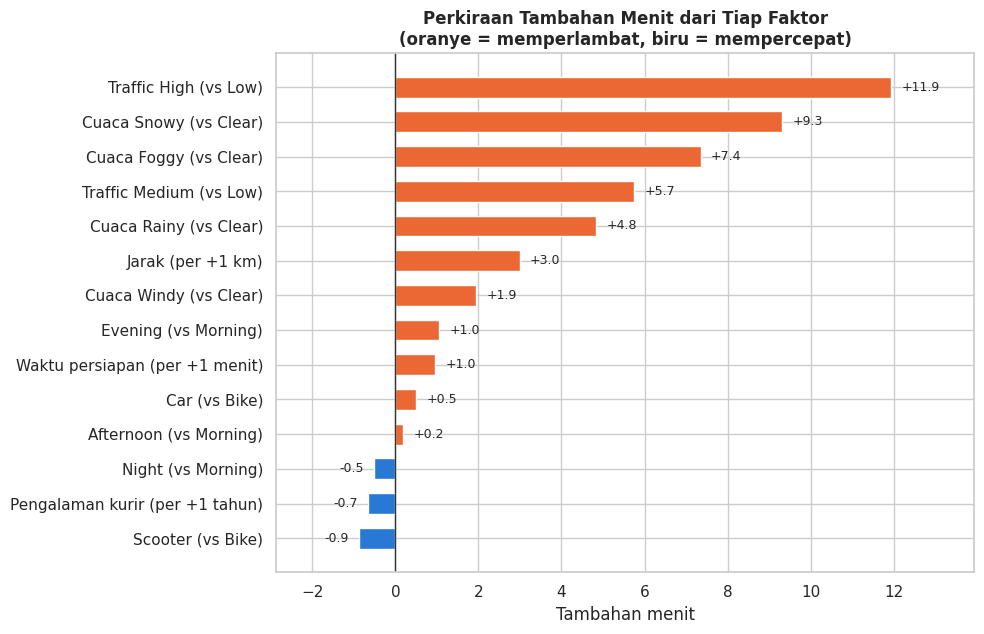

In [33]:
label_rapi = {
    'Distance_km': 'Jarak (per +1 km)',
    'Preparation_Time_min': 'Waktu persiapan (per +1 menit)',
    'Courier_Experience_yrs': 'Pengalaman kurir (per +1 tahun)',
    'Weather_Windy': 'Cuaca Windy (vs Clear)',
    'Weather_Foggy': 'Cuaca Foggy (vs Clear)',
    'Weather_Rainy': 'Cuaca Rainy (vs Clear)',
    'Weather_Snowy': 'Cuaca Snowy (vs Clear)',
    'Traffic_Level_Medium': 'Traffic Medium (vs Low)',
    'Traffic_Level_High': 'Traffic High (vs Low)',
    'Time_of_Day_Afternoon': 'Afternoon (vs Morning)',
    'Time_of_Day_Evening': 'Evening (vs Morning)',
    'Time_of_Day_Night': 'Night (vs Morning)',
    'Vehicle_Type_Scooter': 'Scooter (vs Bike)',
    'Vehicle_Type_Car': 'Car (vs Bike)',
}

plt.figure(figsize=(10, 6.5))
warna = [WARNA_SOROT if v > 0 else WARNA_UTAMA for v in pengaruh.values]
bars = plt.barh([label_rapi[k] for k in pengaruh.index], pengaruh.values, color=warna, height=0.6)
for bar, nilai in zip(bars, pengaruh.values):
    posisi = nilai + 0.25 if nilai > 0 else nilai - 0.25
    plt.text(posisi, bar.get_y() + bar.get_height() / 2, f'{nilai:+.1f}',
             va='center', ha='left' if nilai > 0 else 'right', fontsize=9)
plt.axvline(0, color='#333333', linewidth=1)
plt.xlim(pengaruh.min() - 2, pengaruh.max() + 2)
plt.title('Perkiraan Tambahan Menit dari Tiap Faktor\n(oranye = memperlambat, biru = mempercepat)')
plt.xlabel('Tambahan menit')
plt.tight_layout()
plt.show()

**Insight:**
- Model ini bisa menjelaskan sekitar **78% variasi waktu pengiriman** (R-squared 0,776), jadi faktor-faktor di dataset sudah cukup untuk menjelaskan sebagian besar penyebab lama atau cepatnya pengiriman.
- **Traffic High** menambah sekitar **+11,9 menit** dibanding traffic Low. Ini faktor kategorikal dengan pengaruh paling besar.
- **Cuaca Snowy** menambah sekitar **+9,3 menit**, Foggy **+7,4 menit**, dan Rainy **+4,8 menit** dibanding cuaca cerah.
- Setiap **tambahan 1 km** menambah sekitar **+3 menit**. Kelihatannya kecil, tapi karena jarak bisa sampai 20 km, order 20 km bisa sekitar **57 menit lebih lama** dibanding order 1 km. Inilah kenapa jarak menjadi faktor terbesar secara keseluruhan.
- Setiap **tambahan 1 menit persiapan** menambah sekitar **+1 menit** waktu antar, jadi waktu persiapan langsung terbawa penuh ke total waktu. Karena waktu persiapan berkisar 5 sampai 29 menit, restoran paling lambat bisa membuat pengiriman sekitar **23 menit lebih lama** dibanding restoran paling cepat.
- Jika dilihat dari selisih maksimal yang bisa ditimbulkan, urutan faktor dari yang paling besar adalah: **jarak (sekitar 57 menit), waktu persiapan (sekitar 23 menit), traffic (sekitar 12 menit), dan cuaca (sekitar 9 menit)**.
- Waktu dalam sehari dan jenis kendaraan pengaruhnya di bawah 1 menit, sesuai dengan hasil uji statistik yang tidak signifikan.

## Tahap 4. Insight dan Interpretasi

### Ringkasan Temuan Utama

| No | Insight | Data Pendukung |
|---|---|---|
| 1 | **Hampir setengah order terlambat** | 415 dari 1.000 order (41,5%) memakan waktu lebih dari 60 menit |
| 2 | **Jarak adalah faktor paling berpengaruh** | Korelasi 0,78. Rata-rata naik dari 34 menit (0-5 km) ke 79 menit (15-20 km). 90,6% order terlambat berjarak > 10 km |
| 3 | **Traffic tinggi menambah sekitar 12 menit** | Traffic High rata-rata 64,8 menit (54% terlambat) vs Low 52,9 menit (36% terlambat) |
| 4 | **Cuaca buruk memperlambat, terutama Snowy** | Snowy rata-rata 67,1 menit (60% terlambat) vs Clear 53,2 menit |
| 5 | **Waktu persiapan restoran memakan sepertiga waktu** | Persiapan lambat: 64,2 menit (52% terlambat) vs cepat: 47,3 menit (26% terlambat) |
| 6 | **Kombinasi faktor membuat risiko melonjak** | Cuaca buruk + traffic High: 68,5% terlambat (cuaca Clear + traffic High hanya 37%). Jarak > 15 km + persiapan > 20 menit: 99% terlambat |
| 7 | **Jam pengiriman dan jenis kendaraan tidak berpengaruh** | Selisih antar kategori hanya 1 sampai 2 menit, tidak signifikan secara statistik |
| 8 | **Pengalaman kurir pengaruhnya kecil** | Korelasi hanya -0,09. Senior hanya sekitar 3,5 menit lebih cepat dari junior |

### Interpretasi
1. **Masalah keterlambatan lebih banyak disebabkan oleh kondisi order daripada oleh kurirnya.** Jarak, traffic, cuaca, dan lama persiapan restoran jauh lebih menentukan dibanding pengalaman kurir atau kendaraan yang dipakai.
2. **Faktor yang bisa dikontrol perusahaan** adalah jarak (lewat pengaturan radius layanan) dan waktu persiapan (lewat kerja sama dengan restoran). Faktor ini sebaiknya jadi prioritas perbaikan.
3. **Faktor yang tidak bisa dikontrol** adalah cuaca dan traffic. Untuk faktor ini, yang bisa dilakukan adalah **mengantisipasi**, misalnya menyesuaikan estimasi waktu yang ditampilkan ke pelanggan dan menyiapkan kurir tambahan.
4. **Segmen paling berisiko** adalah order jarak jauh (> 10 km), apalagi jika terjadi saat cuaca buruk, traffic padat, atau dari restoran yang lambat menyiapkan makanan.

## Tahap 5. Rekomendasi Bisnis

| No | Rekomendasi | Dasar Data | Dampak yang Diharapkan |
|---|---|---|---|
| 1 | **Atur radius layanan dan biaya order jarak jauh.** Batasi radius standar di 10 km. Order di atas 10 km tetap bisa dilayani tapi dengan biaya tambahan dan estimasi waktu yang lebih panjang, atau diarahkan ke cabang restoran yang lebih dekat. | 90,6% order terlambat berjarak > 10 km. Order 15-20 km 91% terlambat | Jumlah order terlambat turun signifikan karena sumber utamanya ada di order jarak jauh |
| 2 | **Terapkan estimasi waktu (ETA) dinamis.** ETA yang ditampilkan ke pelanggan dihitung dari jarak, traffic, dan cuaca, bukan angka tetap. Contoh sederhana: tambah +12 menit saat traffic High dan +5 sampai +9 menit saat cuaca buruk. | Traffic High +11,9 menit, Snowy +9,3, Foggy +7,4, Rainy +4,8 menit. Model menjelaskan 78% variasi | Ekspektasi pelanggan lebih realistis sehingga keluhan dan pembatalan berkurang |
| 3 | **Bekerja sama dengan restoran untuk mempercepat persiapan.** Pantau restoran yang rata-rata persiapannya di atas 20 menit, beri target waktu persiapan, dan kirim kurir menjelang makanan siap supaya kurir tidak menunggu lama. Untuk order jarak jauh, minta restoran memprioritaskan persiapannya. | Waktu persiapan memakan 33% dari total waktu. Persiapan lambat 52% terlambat vs cepat 26%. Jarak > 15 km + persiapan > 20 menit: 99% terlambat | Total waktu pengiriman berkurang tanpa harus mengubah rute atau kurir |
| 4 | **Siapkan protokol saat cuaca buruk dan traffic padat.** Tambah jumlah kurir aktif (misalnya dengan insentif bonus) saat hujan, salju, atau kabut, dan beri tanda prioritas untuk order jarak jauh di kondisi tersebut. | Cuaca buruk + traffic High: rata-rata 71,1 menit dan 68,5% terlambat. Rainy + High: 73% terlambat | Mengurangi lonjakan keterlambatan pada kondisi yang paling berisiko |
| 5 | **Jangan prioritaskan investasi kendaraan atau pembagian shift berdasarkan jam.** Fokuskan anggaran ke rekomendasi 1 sampai 4. | Jenis kendaraan dan jam pengiriman tidak signifikan (selisih hanya 1 sampai 2 menit). Mobil tidak lebih cepat dari motor | Anggaran dipakai untuk faktor yang benar-benar berdampak |

## Kesimpulan
1. Sebanyak **41,5% order terlambat** (lebih dari 60 menit), sehingga keterlambatan adalah masalah yang nyata.
2. Empat faktor utama yang memengaruhi waktu pengiriman, diurutkan dari yang paling besar: **jarak, waktu persiapan restoran, traffic, dan cuaca**. Risiko terlambat paling tinggi muncul saat faktor-faktor ini terjadi bersamaan.
3. Jam pengiriman, jenis kendaraan, dan pengalaman kurir **tidak terlalu berpengaruh**.
4. Prioritas perbaikan sebaiknya ada di **pengaturan order jarak jauh, estimasi waktu yang dinamis, dan waktu persiapan restoran**, ditambah antisipasi saat cuaca buruk dan traffic padat.

**Keterbatasan analisis:**
- Dataset tidak memiliki kolom tanggal, sehingga tren dari waktu ke waktu (harian atau bulanan) tidak bisa dianalisis.
- Data bersifat simulasi dan hanya berisi 1.000 order, sehingga beberapa kombinasi kategori jumlah datanya sedikit.
- Batas terlambat 60 menit adalah asumsi. Jika perusahaan punya standar SLA sendiri, angka persentase terlambat perlu dihitung ulang.

## Catatan untuk Dashboard Power BI
Dashboard dibuat menggunakan file **`Food_Delivery_Clean.csv`** hasil notebook ini. Usulan isi dashboard:

| Bagian | Isi |
|---|---|
| Kartu KPI | Total order, rata-rata waktu antar, median waktu antar, % order terlambat |
| Faktor utama | Bar chart rata-rata waktu antar dan % terlambat per `Distance_Group`, `Traffic_Level`, `Weather`, `Prep_Group` |
| Tren | Line chart rata-rata waktu antar per `Distance_Group` dengan legend `Traffic_Level`, dan pola per `Time_of_Day` |
| Kombinasi | Matrix (heatmap) `Weather` x `Traffic_Level` dengan nilai % terlambat |
| Hubungan | Scatter plot `Distance_km` vs `Delivery_Time_min` |
| Filter (slicer) | `Weather`, `Traffic_Level`, `Time_of_Day`, `Vehicle_Type`, `Distance_Group`, `Delivery_Status` |